# 03 — Feature Engineering and Logical Feature Selection

เป้าหมายของ Phase นี้:

1. สร้าง candidate features จากข้อมูลเดิม
2. วัดความเชื่อมโยงของแต่ละ **logical feature** กับ `stroke` ก่อน One-hot encoding
3. เลือกเฉพาะ logical features ที่มีประโยชน์
4. ส่ง features ที่เลือกผ่าน preprocessing ของ Phase 2
5. รวมทุกขั้นตอนเป็น Pipeline เดียวที่รับข้อมูลดิบได้

```text
Raw X
→ Create candidate features
→ Score/select logical features
→ Impute / scale / one-hot encode
→ Model
```

Test set ยังไม่ถูกใช้ใน Phase นี้

In [19]:
from pathlib import Path
import importlib
import sys

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    average_precision_score,
    classification_report,
    roc_auc_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold

RANDOM_STATE = 42
TARGET = "stroke"

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
sns.set_theme(style="whitegrid")
pd.set_option("display.max_rows", 100)

# Reload project code when rerunning this notebook in an existing kernel.
import src.features.selection as selection_module
import src.features.stroke_features as feature_module
import src.modeling.pipeline as pipeline_module

importlib.reload(selection_module)
importlib.reload(feature_module)
importlib.reload(pipeline_module)

LogicalFeatureSelector = selection_module.LogicalFeatureSelector
StrokeFeatureEngineer = feature_module.StrokeFeatureEngineer
get_required_raw_features = feature_module.get_required_raw_features
ENGINEERED_FEATURE_DEPENDENCIES = feature_module.ENGINEERED_FEATURE_DEPENDENCIES
build_model_pipeline = pipeline_module.build_model_pipeline
split_features_target = pipeline_module.split_features_target

## 1. Load train and validation

Train ใช้สร้าง ให้คะแนน และเลือก feature ผ่าน Cross-validation ส่วน validation ใช้ตรวจ Pipeline หลังเลือกเสร็จ

In [20]:
train_path = PROCESSED_DIR / "train.csv"
validation_path = PROCESSED_DIR / "validation.csv"
if not train_path.exists() or not validation_path.exists():
    raise FileNotFoundError("Run 01_data_engineering.ipynb first.")

train_df = pd.read_csv(train_path)
validation_df = pd.read_csv(validation_path)
X_train, y_train = split_features_target(train_df, target=TARGET)
X_validation, y_validation = split_features_target(validation_df, target=TARGET)

print("Train:", X_train.shape)
print("Validation:", X_validation.shape)
print("Original logical features:", X_train.shape[1])

Train: (3577, 10)
Validation: (766, 10)
Original logical features: 10


## 2. Create candidate features

สร้าง candidate โดยมีเหตุผลก่อน แล้วให้คะแนนตัดสินภายหลัง:

| Candidate | เหตุผลที่ทดลอง |
|---|---|
| `age_squared` | ความสัมพันธ์ของอายุกับความเสี่ยงอาจไม่เป็นเส้นตรง |
| `avg_glucose_log1p` | ลดความเบ้ของค่า glucose ที่สูงมาก |
| `bmi_squared` | ความสัมพันธ์ของ BMI อาจไม่เป็นเส้นตรง |
| `age_glucose_interaction` | ทดลองผลร่วมระหว่างอายุและ glucose |
| `bmi_glucose_interaction` | ทดลองผลร่วมระหว่าง BMI และ glucose |
| `comorbidity_count` | รวมจำนวน hypertension และ heart disease |

ทั้งหมดสร้างจาก X เท่านั้น ไม่อ่าน target

In [21]:
feature_engineer = StrokeFeatureEngineer()
X_candidates = feature_engineer.fit_transform(X_train)
engineered_names = X_candidates.columns.difference(X_train.columns).tolist()

print("Original features:", X_train.shape[1])
print("Engineered candidates:", len(engineered_names))
print("Total logical features before encoding:", X_candidates.shape[1])
display(X_candidates[engineered_names].head())

Original features: 10
Engineered candidates: 6
Total logical features before encoding: 16


,age_glucose_interaction,age_squared,avg_glucose_log1p,bmi_glucose_interaction,bmi_squared,comorbidity_count
0,5607.68,2704.0,4.689879,2372.480,484.00,0
1,5475.84,3844.0,4.492225,3206.016,1317.69,0
2,7734.69,6561.0,4.569439,2807.406,864.36,1
3,4046.35,3025.0,4.311738,2059.960,784.00,0
4,3835.42,1369.0,4.650717,3742.126,1303.21,0


## 3. How scoring works before encoding

ใช้ Mutual Information (MI) วัดว่าเมื่อรู้ค่า feature แล้ว เราได้ข้อมูลเกี่ยวกับ `stroke` เพิ่มขึ้นเท่าไร:

- Numeric ใช้ค่าตัวเลขหลังเติม missing ชั่วคราวด้วย median
- Categorical แปลงเป็นรหัสชั่วคราวเพื่อคำนวณคะแนน แต่ยังนับเป็น feature เดียว
- Numeric ที่มีค่าไม่กี่แบบ เช่น hypertension ถูกมองเป็น discrete
- คะแนน 0 หมายถึงตรวจไม่พบข้อมูลเกี่ยวกับ target; คะแนนสูงกว่าแปลว่ามีความเชื่อมโยงมากกว่า

การแปลงชั่วคราวนี้ใช้ให้คะแนนเท่านั้น หลังเลือกแล้ว categorical ที่ถูกเลือกจึงค่อยผ่าน One-hot Encoder ของ Phase 2

## 4. Build the end-to-end Pipeline

Selector อยู่ก่อน preprocessor จึงเลือกทั้งคอลัมน์ เช่น `smoking_status` ไม่ได้เลือก one-hot category แยกกัน

In [22]:
feature_pipeline = build_model_pipeline(
    estimator=LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=RANDOM_STATE,
    ),
    feature_engineer=StrokeFeatureEngineer(),
    feature_selector=LogicalFeatureSelector(random_state=RANDOM_STATE),
)

feature_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('feature_engineering', ...), ('feature_selection', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,k,'all'
,discrete_unique_threshold,10
,random_state,42
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be format

ลำดับของ Pipeline ต้องเป็น:

```text
feature_engineering
→ feature_selection       # ยังเป็น logical columns
→ preprocessor            # impute / scale / one-hot
→ model
```

ทุกครั้งที่ Cross-validation แบ่ง fold ตัว selector จะคำนวณ MI และเลือก feature ใหม่จาก training fold เท่านั้น

## 5. Choose the number of logical features with CV

ทดลองเก็บ 5, 8, 10, 12 และทุก feature จากทั้งหมด 16 logical features แล้วเลือกจำนวนที่ให้ PR-AUC เฉลี่ยสูงที่สุด

In [23]:
logical_feature_count = X_candidates.shape[1]
k_candidates = [k for k in (5, 8, 10, 12) if k < logical_feature_count]
k_candidates.append("all")

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
search = GridSearchCV(
    estimator=feature_pipeline,
    param_grid={"feature_selection__k": k_candidates},
    scoring={
        "pr_auc": "average_precision",
        "roc_auc": "roc_auc",
        "recall": "recall",
    },
    refit="pr_auc",
    cv=cv,
    n_jobs=-1,
    return_train_score=False,
)
search.fit(X_train, y_train)

print("Logical features available:", logical_feature_count)
print("Numbers compared:", k_candidates)
print("Best number:", search.best_params_["feature_selection__k"])
print(f"Best train CV PR-AUC: {search.best_score_:.4f}")

Logical features available: 16
Numbers compared: [5, 8, 10, 12, 'all']
Best number: 8
Best train CV PR-AUC: 0.2372


In [24]:
cv_results = pd.DataFrame(search.cv_results_)
cv_summary = cv_results[[
    "param_feature_selection__k",
    "mean_test_pr_auc",
    "std_test_pr_auc",
    "mean_test_roc_auc",
    "mean_test_recall",
]].rename(columns={
    "param_feature_selection__k": "logical_features_kept",
    "mean_test_pr_auc": "pr_auc_mean",
    "std_test_pr_auc": "pr_auc_std",
    "mean_test_roc_auc": "roc_auc_mean",
    "mean_test_recall": "recall_mean",
})
display(cv_summary.round(4))

,logical_features_kept,pr_auc_mean,pr_auc_std,roc_auc_mean,recall_mean
0,5,0.2262,0.0266,0.8527,0.8220
1,8,0.2372,0.0211,0.8552,0.8047
2,10,0.2336,0.0180,0.8532,0.7990
3,12,0.2350,0.0168,0.8509,0.7990
4,all,0.2262,0.0114,0.8486,0.8161


## 6. Score and summarize every logical feature

หลัง CV เลือกจำนวนแล้ว Pipeline ที่ดีที่สุดถูก fit ใหม่บน train ทั้งชุด ตารางนี้จึงแสดงคะแนน MI ของ original และ engineered features อย่างละหนึ่งแถว พร้อมผลการเลือก

In [25]:
best_pipeline = search.best_estimator_
selector = best_pipeline.named_steps["feature_selection"]

feature_scores = pd.DataFrame({
    "feature": selector.feature_names_in_,
    "mi_score": selector.scores_,
    "selected": selector.get_support(),
})
feature_scores["origin"] = feature_scores["feature"].apply(
    lambda name: "engineered" if name in engineered_names else "original"
)
feature_scores["rank"] = feature_scores["mi_score"].rank(
    ascending=False, method="min"
).astype(int)
feature_scores = feature_scores.sort_values("mi_score", ascending=False).reset_index(drop=True)

display(feature_scores[["rank", "feature", "origin", "mi_score", "selected"]].round(5))

,rank,feature,origin,mi_score,selected
0,1,age,original,0.04264,True
1,2,age_squared,engineered,0.04088,True
2,3,age_glucose_interaction,engineered,0.02703,True
3,4,bmi_glucose_interaction,engineered,0.01659,True
4,5,bmi,original,0.01073,True
5,6,comorbidity_count,engineered,0.01061,True
6,7,bmi_squared,engineered,0.00800,True
7,8,ever_married,original,0.00768,True
8,9,work_type,original,0.00749,False
9,10,heart_disease,original,0.00640,False


Selected 8 logical features:


,rank,feature,origin,mi_score
0,1,age,original,0.04264
1,2,age_squared,engineered,0.04088
2,3,age_glucose_interaction,engineered,0.02703
3,4,bmi_glucose_interaction,engineered,0.01659
4,5,bmi,original,0.01073
5,6,comorbidity_count,engineered,0.01061
6,7,bmi_squared,engineered,0.00800
7,8,ever_married,original,0.00768


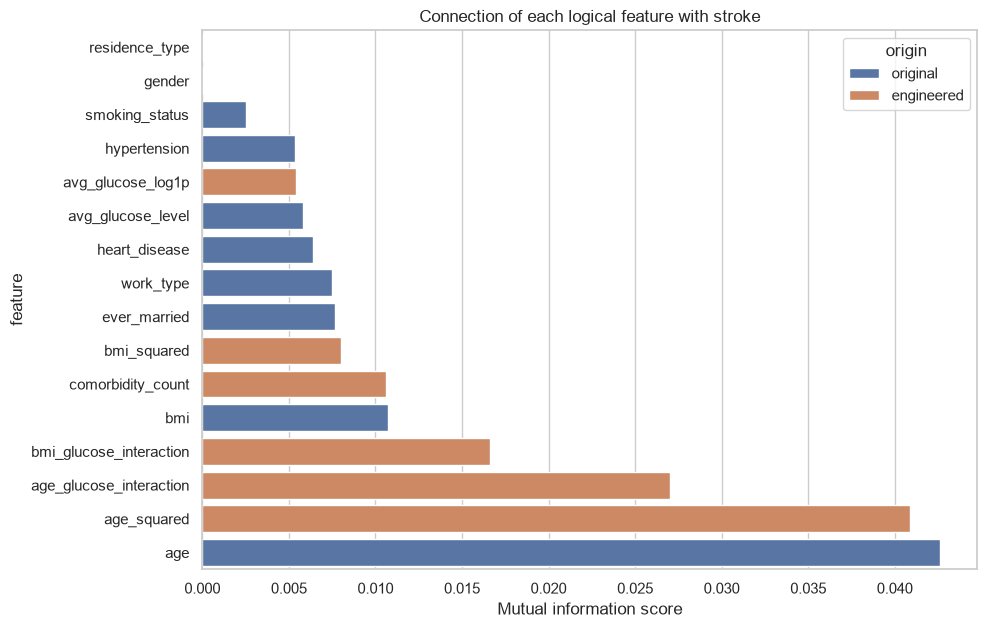

In [26]:
selected_features = feature_scores[feature_scores["selected"]].copy()
print(f"Selected {len(selected_features)} logical features:")
display(selected_features[["rank", "feature", "origin", "mi_score"]].round(5))

plt.figure(figsize=(10, 7))
sns.barplot(
    data=feature_scores.sort_values("mi_score"),
    x="mi_score",
    y="feature",
    hue="origin",
)
plt.title("Connection of each logical feature with stroke")
plt.xlabel("Mutual information score")
plt.show()

## 7. Required original inputs

Feature ที่โมเดลใช้กับข้อมูลที่ผู้ใช้ต้องกรอกไม่จำเป็นต้องเป็นรายการเดียวกัน ตัวอย่างเช่น ถ้าเลือก `age_squared` แต่ไม่เลือก `age` โดยตรง ผู้ใช้ยังต้องกรอก `age` เพื่อให้ Pipeline สร้าง `age_squared`

ส่วนนี้สรุปทั้ง **selected model features** และ **required original inputs** จากผลการเลือกจริง

In [27]:
selected_feature_names = selector.selected_features_.tolist()
required_raw_features = get_required_raw_features(
    selected_features=selected_feature_names,
    original_feature_order=X_train.columns,
)
unused_raw_features = [
    feature for feature in X_train.columns
    if feature not in required_raw_features
]

input_rows = []
for raw_feature in required_raw_features:
    used_by = [
        engineered
        for engineered, dependencies in ENGINEERED_FEATURE_DEPENDENCIES.items()
        if engineered in selected_feature_names and raw_feature in dependencies
    ]
    input_rows.append({
        "required_raw_input": raw_feature,
        "used_directly": raw_feature in selected_feature_names,
        "needed_to_create": ", ".join(used_by) if used_by else "-",
    })

print("Selected model features:")
print(selected_feature_names)
print("\nRequired original inputs for the form/API:")
display(pd.DataFrame(input_rows))
print("Original inputs not needed by this Pipeline:")
print(unused_raw_features)

# This is the minimum raw-input DataFrame accepted by the fitted Pipeline.
X_validation_input = X_validation[required_raw_features].copy()
print("\nMinimal validation input shape:", X_validation_input.shape)

Selected model features:
['age', 'ever_married', 'bmi', 'age_squared', 'bmi_squared', 'age_glucose_interaction', 'bmi_glucose_interaction', 'comorbidity_count']

Required original inputs for the form/API:


,required_raw_input,used_directly,needed_to_create
0,age,True,"age_squared, age_glucose_interaction"
1,hypertension,False,comorbidity_count
2,heart_disease,False,comorbidity_count
3,ever_married,True,-
4,avg_glucose_level,False,"age_glucose_interaction, bmi_glucose_interaction"
5,bmi,True,"bmi_squared, bmi_glucose_interaction"


Original inputs not needed by this Pipeline:
['gender', 'work_type', 'residence_type', 'smoking_status']

Minimal validation input shape: (766, 6)


## 8. Validate the complete Pipeline

Validation ถูกส่งเข้า Pipeline เป็นข้อมูลดิบระดับเดียวกับ `X_train` แล้ว Pipeline จะสร้าง feature, เลือก feature, encode และทำนายให้เอง

Validation PR-AUC:  0.2230
Validation ROC-AUC: 0.8397

Classification report at threshold 0.5:
              precision    recall  f1-score   support

           0     0.9835    0.7380    0.8433       729
           1     0.1279    0.7568    0.2188        37

    accuracy                         0.7389       766
   macro avg     0.5557    0.7474    0.5310       766
weighted avg     0.9422    0.7389    0.8131       766



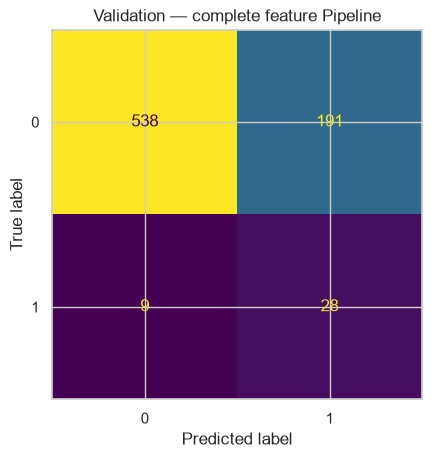

In [28]:
validation_probability = best_pipeline.predict_proba(X_validation_input)[:, 1]
validation_prediction = (validation_probability >= 0.5).astype(int)

print(f"Validation PR-AUC:  {average_precision_score(y_validation, validation_probability):.4f}")
print(f"Validation ROC-AUC: {roc_auc_score(y_validation, validation_probability):.4f}")
print("\nClassification report at threshold 0.5:")
print(classification_report(y_validation, validation_prediction, digits=4, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_validation, validation_prediction, colorbar=False
)
plt.title("Validation — complete feature Pipeline")
plt.show()

## Pipeline hand-off

`best_pipeline` เป็น end-to-end Pipeline ที่รับ raw X ได้โดยตรง:

```python
# ใช้ใน Phase 5 หลัง Phase 4 เลือกโมเดลและ threshold เสร็จแล้ว
X_test, y_test = split_features_target(test_df, target=TARGET)
test_probability = final_pipeline.predict_proba(X_test)[:, 1]
```

ใน Phase 4 จะนำโครงสร้างเดียวกันไปเปรียบเทียบโมเดลและปรับ hyperparameters จากนั้นจึงได้ `final_pipeline` สำหรับ test จริง ห้าม fit Pipeline ใหม่ด้วย test